# Práctica 4. Análisis sintáctico del corpus

En esta práctica analizo cómo se organizan las palabras dentro de las oraciones del corpus de ofertas
de empleo. En la Práctica 3 vi qué tipo de palabra es cada una; aquí veo cómo se relacionan entre sí:
quién es el sujeto, cuál es el verbo, qué complementos lleva y qué tan compleja es cada oración.

El análisis sintáctico se puede representar de dos formas, y uso una herramienta para cada una:

- **Árboles de constituyentes** con `RegexpParser` de NLTK. Le doy una gramática sencilla escrita por
  mí que agrupa las palabras en frases nominales (NP), preposicionales (PP), verbales (VP) y
  cláusulas (sujeto + predicado). Uso las etiquetas gramaticales que obtuve en la Práctica 3.
- **Dependencias** con spaCy y su modelo `en_core_web_sm`. NLTK no trae un analizador de
  dependencias ya entrenado, así que instalé spaCy (`pip install spacy` y
  `python -m spacy download en_core_web_sm`). Este modelo conecta cada palabra con la palabra de la
  que depende y le pone nombre a esa relación.

Igual que en las prácticas anteriores, trabajo con el corpus completo y dejo fuera las oraciones con
restos de estilos de Word. La celda que analiza las dependencias es la más lenta: tarda unos 12
minutos.

In [1]:
import gzip, json
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import nltk
import spacy
import svgling
from IPython.display import SVG, display
from spacy import displacy

RUTA = Path("corpus_procesado")
if not RUTA.exists():
    RUTA = Path.home() / "Downloads" / "corpus_procesado"

# Solo cargo el texto de las oraciones; las listas de tokens no hacen falta y ocupan mucha memoria.
ids, categorias, oraciones_doc = [], [], []
with gzip.open(RUTA / "corpus_tokens.jsonl.gz", "rt", encoding="utf-8") as f:
    for linea in f:
        d = json.loads(linea)
        ids.append(d["doc_id"])
        categorias.append(d["categoria"])
        oraciones_doc.append([o for o in d["oraciones"] if "mso-" not in o])
metadatos = pd.read_csv(RUTA / "corpus_limpio.csv.gz", usecols=["doc_id", "industry"])
industrias = dict(zip(metadatos["doc_id"], metadatos["industry"]))

AZUL, NARANJA, VERDE, MORADO = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"
GRIS, REJILLA = "#52514e", "#dcdcd8"
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 9.5,
                     "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
                     "legend.frameon": False, "legend.fontsize": 8.5})

def estilizar(ax, rejilla="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=rejilla, color=REJILLA, linewidth=0.8)
    ax.set_axisbelow(True)

print(f"Documentos: {len(ids):,}")
print(f"Oraciones:  {sum(len(o) for o in oraciones_doc):,}")

Documentos: 14,265
Oraciones:  470,085


## 1. Análisis mediante árboles sintácticos

La gramática que uso tiene cinco reglas, aplicadas en orden sobre las etiquetas del Penn Treebank:

- **NP (frase nominal):** un sustantivo con lo que lo acompaña antes, como un determinante, un
  posesivo o adjetivos ("a talented developer", "our team"). Un pronombre solo también cuenta.
- **Coordinación:** dos frases nominales unidas con `and` u `or` forman una sola frase nominal
  ("competitive salaries and excellent benefits").
- **PP (frase preposicional):** una preposición seguida de una frase nominal ("for a developer").
- **VP (frase verbal):** uno o más verbos, con un modal opcional, seguidos de sus complementos
  ("can build scalable applications").
- **CLAUSE (cláusula):** una frase nominal seguida de una frase verbal. Es la estructura
  sujeto + predicado: la NP es el sujeto y la NP dentro de la VP es el objeto.

Es un análisis superficial: no resuelve todas las ambigüedades como lo haría un parser completo,
pero deja ver claramente sujetos, verbos, objetos y frases.

We offer competitive salaries and excellent benefits.


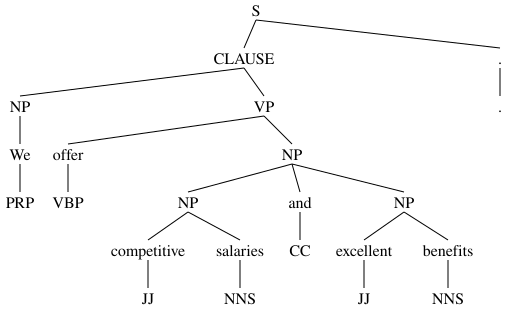

We are looking for individuals who are prepared to take a position.


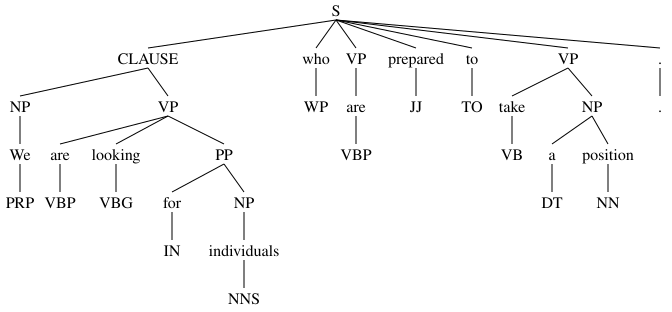

Please send your CV.


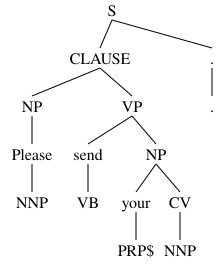

Excellent communication skills


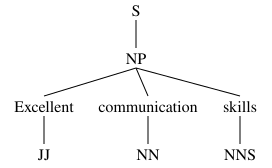

In [2]:
GRAMATICA = r'''
NP: {<DT|PRP\$|CD>?<JJ.*|VBN|VBG|NN.*>*<NN.*>}
    {<PRP>}
NP: {<NP><CC><NP>}
PP: {<IN|TO><NP>}
VP: {<MD>?<VB.*>+<RP|RB>?<NP|PP>*}
CLAUSE: {<NP><VP>}
'''
chunker = nltk.RegexpParser(GRAMATICA, loop=2)

def arbol(oracion):
    palabras = nltk.word_tokenize(oracion)
    return chunker.parse(nltk.pos_tag(palabras))

ejemplos = [
    "We offer competitive salaries and excellent benefits.",
    "We are looking for individuals who are prepared to take a position.",
    "Please send your CV.",
    "Excellent communication skills",
]
for oracion in ejemplos:
    print(oracion)
    display(svgling.draw_tree(arbol(oracion)))

Cada ejemplo muestra una estructura distinta del corpus:

1. **"We offer competitive salaries..."** es la estructura más completa: una cláusula con sujeto
   (`We`), verbo (`offer`) y objeto. Gracias a la regla de coordinación, el objeto es una sola frase
   nominal que junta `competitive salaries` y `excellent benefits`. Es la forma en que la empresa se
   presenta y describe lo que da.
2. **"We are looking for individuals who..."** empieza bien: una cláusula cuyo verbo lleva una frase
   preposicional (`for individuals`). Pero la segunda mitad queda en pedazos sueltos (`who`, `are`,
   `prepared`, `to take a position`), porque la gramática solo junta palabras contiguas y no sabe
   armar una cláusula relativa. Por cierto, esta oración aparece decenas de veces en ofertas
   fraudulentas: es una plantilla de campaña que se copia de un anuncio a otro.
3. **"Please send your CV."** muestra cómo un error del etiquetado arrastra al árbol. Es un
   imperativo y no tiene sujeto, pero el etiquetador marca `Please` como nombre propio por la
   mayúscula, y la gramática lo toma como sujeto de `send`. Es el mismo tipo de error que vi en la
   Práctica 3 con "Apply now".
4. **"Excellent communication skills"** no tiene verbo: toda la "oración" es una sola frase nominal.
   Son las viñetas que vengo encontrando desde la Práctica 1.

Los dos errores tienen la misma causa: la gramática es superficial y depende completamente de las
etiquetas. Las dependencias de la sección 2 resuelven mejor ambos casos.

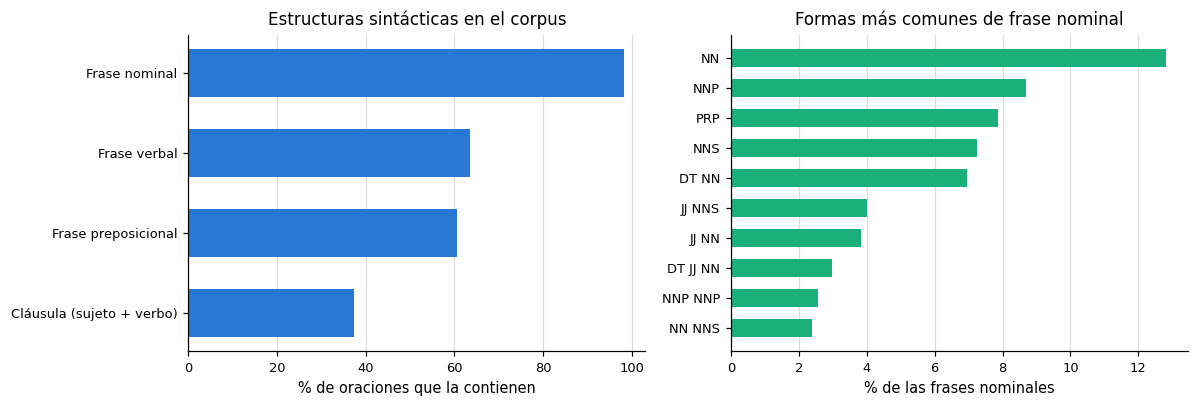

Oraciones analizadas: 470,085
Frase nominal                98.2
Frase verbal                 63.5
Frase preposicional          60.6
Cláusula (sujeto + verbo)    37.3


In [3]:
# Aplico la gramática a todo el corpus usando las etiquetas de la Práctica 3.
estructuras = Counter()        # cuántas oraciones contienen cada estructura
patrones_np = Counter()        # secuencias de etiquetas que forman las frases nominales
oraciones_chunk = 0
with gzip.open(RUTA / "corpus_pos.jsonl.gz", "rt", encoding="utf-8") as f:
    for linea in f:
        d = json.loads(linea)
        for palabras, etiquetas in zip(d["tokens"], d["pos"]):
            if not palabras:
                continue
            oraciones_chunk += 1
            presentes = set()
            for sub in chunker.parse(list(zip(palabras, etiquetas))).subtrees():
                presentes.add(sub.label())
                if sub.label() == "NP":
                    patrones_np[" ".join(t for _, t in sub.leaves())] += 1
            estructuras.update(presentes - {"S"})

nombres_est = {"NP": "Frase nominal", "PP": "Frase preposicional",
               "VP": "Frase verbal", "CLAUSE": "Cláusula (sujeto + verbo)"}
pct_est = pd.Series({nombres_est[k]: 100 * v / oraciones_chunk for k, v in estructuras.items()})
pct_est = pct_est.sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.barh(pct_est.index, pct_est.values, color=AZUL, height=0.6)
ax1.set_xlabel("% de oraciones que la contienen")
ax1.set_title("Estructuras sintácticas en el corpus")
estilizar(ax1, rejilla="x")

top_np = patrones_np.most_common(10)[::-1]
ax2.barh([p for p, _ in top_np], [100 * n / sum(patrones_np.values()) for _, n in top_np],
         color=VERDE, height=0.6)
ax2.set_xlabel("% de las frases nominales")
ax2.set_title("Formas más comunes de frase nominal")
estilizar(ax2, rejilla="x")
fig.tight_layout()
plt.show()

print(f"Oraciones analizadas: {oraciones_chunk:,}")
print(pct_est.sort_values(ascending=False).round(1).to_string())

Casi todas las oraciones tienen al menos una frase nominal, pero menos de la mitad tienen una
cláusula completa con sujeto y verbo. Eso confirma, ahora desde la estructura, lo que la Práctica 3
mostraba con las etiquetas: buena parte del corpus no son oraciones en sentido estricto, sino listas
de frases nominales.

También llama la atención que hay bastantes más oraciones con frase verbal que con cláusula. La
diferencia son verbos que no tienen un sujeto delante: imperativos ("Send your CV") y, sobre todo,
viñetas de responsabilidades que empiezan directamente con el verbo ("Manage client accounts",
"Develop new features").

Las frases nominales más comunes son muy cortas: un sustantivo solo (`NN`, `NNS`), un pronombre
(`PRP`) o un sustantivo con un adjetivo o con otro sustantivo delante (`JJ NN`, `NN NNS`). Los
nombres propios encadenados (`NNP NNP`) vienen de títulos de puestos y nombres de empresas, que como
vimos en la Práctica 3 el etiquetador suele marcar como nombres propios. Es el vocabulario
"empaquetado" de los anuncios: `communication skills`, `web developer`, `sales team`.

## 2. Análisis de dependencias

En el análisis de dependencias cada palabra apunta a la palabra de la que depende (su "cabeza"), y
la flecha lleva el nombre de la relación. Solo una palabra no depende de nadie, la raíz, que casi
siempre es el verbo principal. Algunas relaciones importantes:

- `nsubj`: sujeto del verbo.
- `dobj`: objeto directo.
- `amod`: adjetivo que modifica a un sustantivo.
- `compound`: sustantivo que forma un compuesto con otro (`communication` → `skills`).
- `prep` y `pobj`: una preposición y el sustantivo que la sigue.

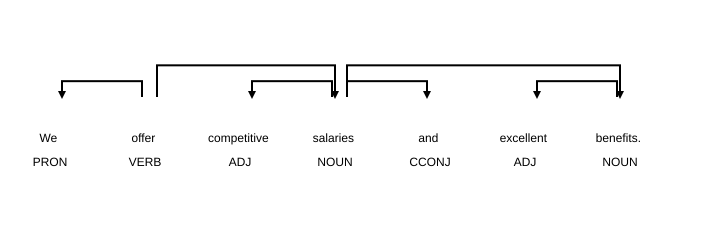

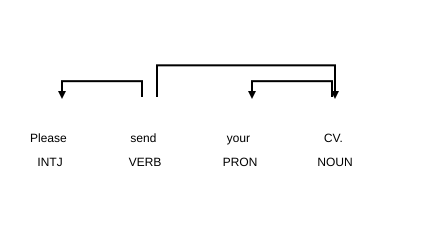

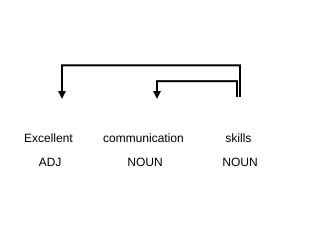

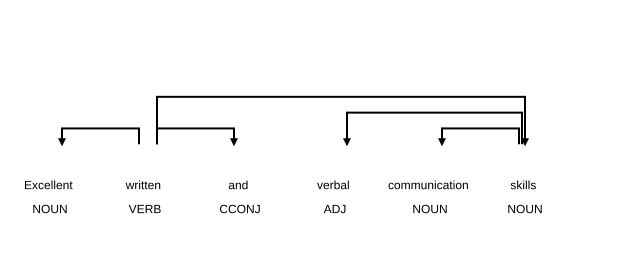

In [4]:
nlp = spacy.load("en_core_web_sm", disable=["ner"])
opciones = {"compact": True, "distance": 95, "font": "Arial"}
for oracion in ["We offer competitive salaries and excellent benefits.",
                "Please send your CV.",
                "Excellent communication skills",
                "Excellent written and verbal communication skills"]:
    display(SVG(displacy.render(nlp(oracion), style="dep", options=opciones, jupyter=False)))

En la primera oración el verbo `offer` es la raíz, y de él salen el sujeto (`We`, `nsubj`) y el
objeto (`salaries`, `dobj`). A su vez, `salaries` tiene su propio adjetivo (`competitive`, `amod`) y
está coordinado con `benefits` (`conj`). Esta representación muestra mejor que el árbol de la
sección 1 cuál palabra modifica a cuál.

En el imperativo, `send` es la raíz y no tiene sujeto, solo el objeto `CV`. Aquí spaCy acierta donde
la gramática de NLTK fallaba: reconoce `Please` como interjección (`intj`) y no como sujeto. En la
primera viñeta, la raíz no es un verbo sino el sustantivo `skills`, y todo lo demás cuelga de él como
modificadores. Así se ve una oración sin verbo en un análisis de dependencias: un árbol plano con un
sustantivo arriba.

El último ejemplo muestra que spaCy también se equivoca. En "Excellent written and verbal
communication skills" toma `written` como verbo y `Excellent` como su sujeto, como si fuera una
oración que dice "lo excelente escribió...". Es una de las viñetas más repetidas del corpus, así que
este error hace que algunas viñetas cuenten como oraciones con verbo y sujeto. Revisé cuántas son y
las viñetas de este tipo no llegan al 0.3 % de las oraciones, así que no cambian los resultados
generales, pero es un buen recordatorio de que los modelos se entrenaron con prosa y no con listas.

In [5]:
# Analizo todo el corpus. Por cada oración guardo sus métricas y voy acumulando los conteos de
# relaciones. También escribo el análisis completo a disco para la siguiente práctica.
SUBORDINADAS = {"advcl", "ccomp", "xcomp", "relcl", "acl", "csubj"}

def profundidades(doc):
    # La raíz tiene profundidad 0 y cada dependiente una más que su cabeza.
    prof = {t.i: 0 for t in doc if t.head.i == t.i}
    pendientes = [t for t in doc if t.i not in prof]
    while pendientes:
        resueltos = [t for t in pendientes if t.head.i in prof]
        if not resueltos:
            break
        for t in resueltos:
            prof[t.i] = prof[t.head.i] + 1
        pendientes = [t for t in pendientes if t.i not in prof]
    return prof

referencias = [(di, si, len(ors)) for di, ors in enumerate(oraciones_doc) for si in range(len(ors))]
textos = (o for ors in oraciones_doc for o in ors)

filas = []
dependencias = defaultdict(Counter)    # categoría -> relación -> frecuencia
pares_pos = Counter()                  # (categoría de la cabeza, categoría del dependiente)
verbo_hijos, verbo_veces = Counter(), Counter()
verbo_objeto = Counter()

salida = gzip.open(RUTA / "corpus_dependencias.jsonl.gz", "wt", encoding="utf-8")
doc_actual, oraciones_json = 0, []
for k, ((di, si, n), doc) in enumerate(zip(referencias, nlp.pipe(textos, batch_size=1000))):
    if di != doc_actual:
        salida.write(json.dumps({"doc_id": ids[doc_actual], "categoria": categorias[doc_actual],
                                 "oraciones": oraciones_json}, ensure_ascii=False) + "\n")
        doc_actual, oraciones_json = di, []
    oraciones_json.append({"tokens": [t.text for t in doc], "pos": [t.pos_ for t in doc],
                           "dep": [t.dep_ for t in doc], "head": [t.head.i for t in doc]})

    palabras = [t for t in doc if not t.is_punct and not t.is_space]
    if not palabras:
        continue
    prof = profundidades(doc)
    categoria = categorias[di]
    distancias, subord = [], 0
    tiene_sujeto = tiene_objeto = tiene_verbo = False
    for t in palabras:
        dependencias[categoria][t.dep_] += 1
        if t.head.i != t.i:
            pares_pos[(t.head.pos_, t.pos_)] += 1
            if not t.head.is_punct:
                distancias.append(abs(t.i - t.head.i))
        if t.pos_ == "VERB":
            verbo_veces[t.lemma_.lower()] += 1
            verbo_hijos[t.lemma_.lower()] += sum(1 for c in t.children if not c.is_punct)
        if t.pos_ in ("VERB", "AUX"):
            tiene_verbo = True
        if t.dep_ in ("nsubj", "nsubjpass"):
            tiene_sujeto = True
        if t.dep_ == "dobj":
            tiene_objeto = True
            if t.head.pos_ == "VERB" and t.pos_ in ("NOUN", "PROPN"):
                verbo_objeto[(t.head.lemma_.lower(), t.lemma_.lower())] += 1
        if t.dep_ in SUBORDINADAS:
            subord += 1
    filas.append({"doc": di, "oracion": si, "n_oraciones": n, "categoria": categoria,
                  "industria": industrias[ids[di]], "longitud": len(palabras),
                  "profundidad": max(prof.get(t.i, 0) for t in palabras),
                  "distancia": np.mean(distancias) if distancias else 0.0,
                  "subordinadas": subord, "sujeto": tiene_sujeto, "objeto": tiene_objeto,
                  "verbo": tiene_verbo})
    if k % 100000 == 0:
        print(f"{k:,} oraciones analizadas")

salida.write(json.dumps({"doc_id": ids[doc_actual], "categoria": categorias[doc_actual],
                         "oraciones": oraciones_json}, ensure_ascii=False) + "\n")
salida.close()
oraciones = pd.DataFrame(filas)
print(f"Listo: {len(oraciones):,} oraciones")

0 oraciones analizadas


100,000 oraciones analizadas


200,000 oraciones analizadas


300,000 oraciones analizadas


400,000 oraciones analizadas


Listo: 468,956 oraciones


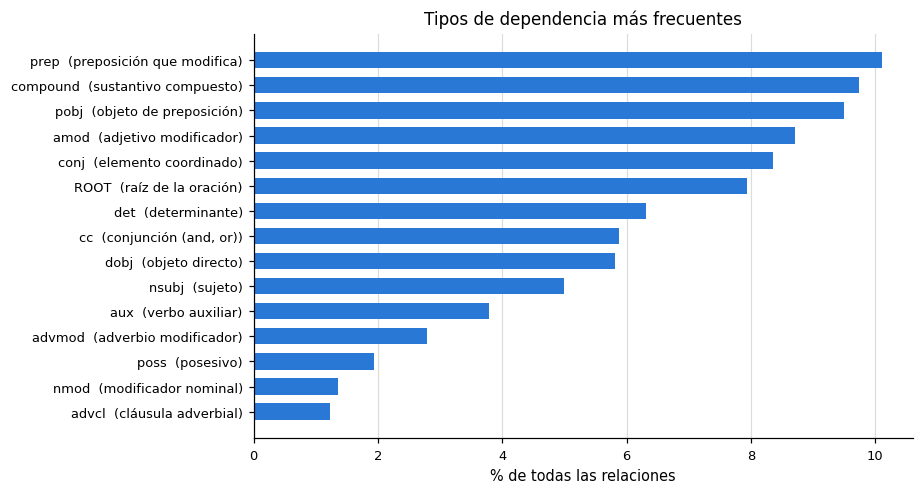

In [6]:
DESCRIPCION = {
    "prep": "preposición que modifica", "compound": "sustantivo compuesto",
    "pobj": "objeto de preposición", "amod": "adjetivo modificador", "conj": "elemento coordinado",
    "ROOT": "raíz de la oración", "det": "determinante", "cc": "conjunción (and, or)",
    "dobj": "objeto directo", "nsubj": "sujeto", "aux": "verbo auxiliar",
    "advmod": "adverbio modificador", "poss": "posesivo", "nmod": "modificador nominal",
    "advcl": "cláusula adverbial", "acl": "cláusula que modifica a un sustantivo",
    "appos": "aposición", "xcomp": "complemento verbal (to + verbo)",
    "relcl": "cláusula relativa", "nummod": "número modificador",
}
total_dep = Counter()
for c in dependencias.values():
    total_dep.update(c)
suma = sum(total_dep.values())
top_dep = pd.DataFrame([(d, DESCRIPCION.get(d, ""), 100 * v / suma) for d, v in total_dep.most_common(15)],
                       columns=["relación", "significado", "%"])

fig, ax = plt.subplots(figsize=(8.5, 4.6))
etiquetas = [f"{r}  ({s})" for r, s in zip(top_dep["relación"], top_dep["significado"])]
ax.barh(etiquetas[::-1], top_dep["%"][::-1], color=AZUL, height=0.65)
ax.set_xlabel("% de todas las relaciones")
ax.set_title("Tipos de dependencia más frecuentes")
estilizar(ax, rejilla="x")
fig.tight_layout()
plt.show()

Las relaciones más frecuentes no son las del esqueleto de la oración (sujeto, verbo, objeto), sino
las que construyen frases nominales: preposiciones con su objeto (`prep`, `pobj`), sustantivos
compuestos (`compound`), adjetivos (`amod`), determinantes y coordinaciones (`conj`, `cc`). Sujetos
y objetos directos aparecen bastante más abajo.

Esto es coherente con todo lo anterior. El corpus describe cosas más que acciones, así que la
mayor parte del trabajo sintáctico consiste en armar frases nominales largas y enumeraciones, como
"strong knowledge of web development and database design". La coordinación es especialmente alta
porque los anuncios listan requisitos y prestaciones unidos con `and`.

## 3. Relaciones sintácticas entre palabras

### 3.1 Relaciones entre categorías gramaticales

Aquí cruzo la categoría de la cabeza con la de su dependiente. Cada fila suma 100 %: dice qué tipo
de palabras suelen depender de una categoría.

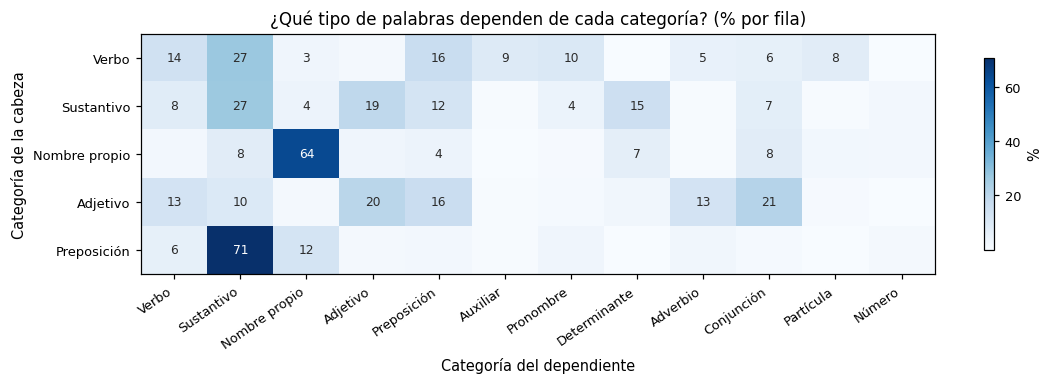

In [7]:
CATS = ["VERB", "NOUN", "PROPN", "ADJ", "ADP", "AUX", "PRON", "DET", "ADV", "CCONJ", "PART", "NUM"]
NOMBRES = {"VERB": "Verbo", "NOUN": "Sustantivo", "PROPN": "Nombre propio", "ADJ": "Adjetivo",
           "ADP": "Preposición", "AUX": "Auxiliar", "PRON": "Pronombre", "DET": "Determinante",
           "ADV": "Adverbio", "CCONJ": "Conjunción", "PART": "Partícula", "NUM": "Número"}
cabezas = ["VERB", "NOUN", "PROPN", "ADJ", "ADP"]
matriz = pd.DataFrame([[pares_pos[(c, d)] for d in CATS] for c in cabezas],
                      index=[NOMBRES[c] for c in cabezas], columns=[NOMBRES[d] for d in CATS])
matriz = 100 * matriz.div(matriz.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10.5, 3.6))
imagen = ax.imshow(matriz.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(CATS)), matriz.columns, rotation=35, ha="right")
ax.set_yticks(range(len(cabezas)), matriz.index)
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.values[i, j]
        if v >= 3:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 40 else "#2b2b2b")
ax.set_xlabel("Categoría del dependiente")
ax.set_ylabel("Categoría de la cabeza")
ax.set_title("¿Qué tipo de palabras dependen de cada categoría? (% por fila)")
fig.colorbar(imagen, ax=ax, shrink=0.8, label="%")
fig.tight_layout()
plt.show()

Cada categoría tiene un perfil muy claro de dependientes:

- **Los verbos** reúnen los elementos más variados: sustantivos (sus objetos), preposiciones, otros
  verbos (complementos como "able to work"), pronombres (sus sujetos, como `we` o `you`), auxiliares
  y partículas. Son el centro que organiza la
  oración cuando la hay.
- **Los sustantivos** reciben sobre todo adjetivos, determinantes, otros sustantivos (los
  compuestos) y preposiciones. Son el núcleo de las frases nominales que dominan el corpus.
- **Las preposiciones** casi solo llevan un sustantivo o nombre propio como dependiente: es su objeto
  (`for a developer`, `in London`).
- **Los nombres propios** dependen sobre todo de otros nombres propios, porque forman cadenas como
  nombres de ciudades, empresas o puestos ("New York City", "Senior Software Engineer").
- **Los adjetivos** llevan muchas conjunciones y adverbios, por las coordinaciones ("written and
  verbal") y los intensificadores ("highly motivated").

En otras palabras, la sintaxis del corpus se reparte en dos tipos de núcleos: verbos que organizan
oraciones completas y sustantivos que organizan frases nominales. Como hay tantas viñetas, los
segundos pesan muchísimo.

### 3.2 Palabras con mayor conectividad

Para ver qué verbos concentran más relaciones, cuento cuántos dependientes tiene cada verbo en
promedio. Solo tomo en cuenta los verbos que aparecen al menos 1,000 veces, para que el promedio sea
estable.

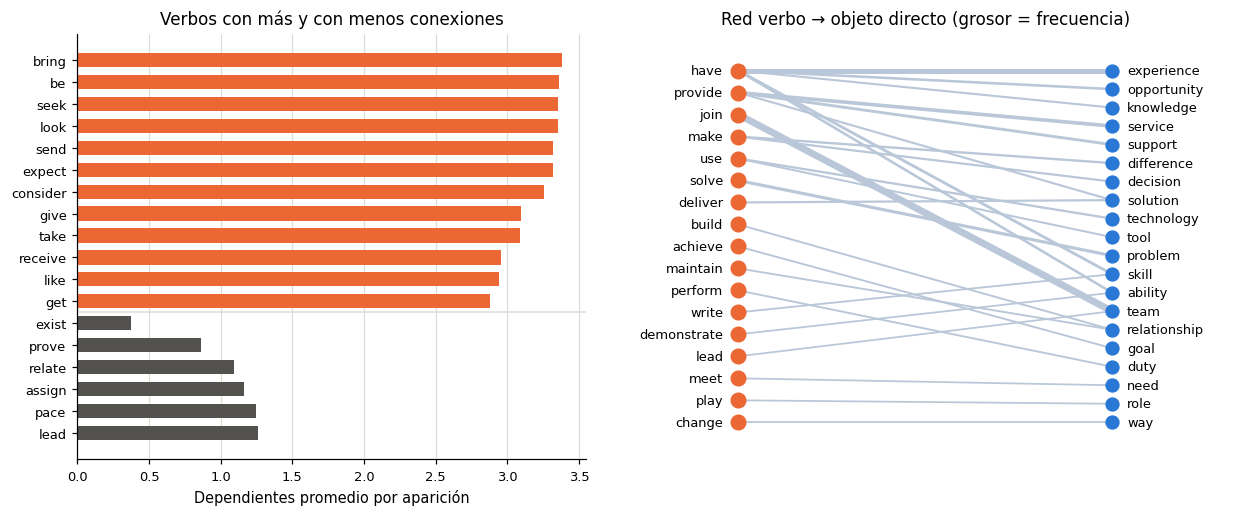

Pares verbo-objeto más frecuentes:
   join team            3,180
   have experience      2,198
   provide service         1,491
   solve problem         1,226
   have skill           1,102
   provide support         1,086
   have ability           948
   have opportunity       934
   make difference        830
   use technology        779


In [8]:
conectividad = pd.Series({v: verbo_hijos[v] / n for v, n in verbo_veces.items() if n >= 1000})
mas = conectividad.sort_values(ascending=False).head(12)
menos = conectividad.sort_values().head(6)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
juntos = pd.concat([menos[::-1], mas[::-1]])
colores = [GRIS] * len(menos) + [NARANJA] * len(mas)
ax1.barh(juntos.index, juntos.values, color=colores, height=0.65)
ax1.axhline(len(menos) - 0.5, color=REJILLA, linewidth=1)
ax1.set_xlabel("Dependientes promedio por aparición")
ax1.set_title("Verbos con más y con menos conexiones")
estilizar(ax1, rejilla="x")

# Red de los pares verbo -> objeto directo más frecuentes, en dos columnas:
# verbos a la izquierda y objetos a la derecha.
G = nx.Graph()
for (verbo, objeto), n in verbo_objeto.most_common(25):
    G.add_edge(f"v:{verbo}", f"o:{objeto}", peso=n)
verbos_red = sorted([n for n in G if n.startswith("v:")],
                    key=lambda v: -sum(G[v][o]["peso"] for o in G[v]))
pos_verbo = {v: i for i, v in enumerate(verbos_red)}
# Cada objeto se coloca a la altura promedio de sus verbos, para que se crucen menos líneas.
objetos_red = sorted([n for n in G if n.startswith("o:")],
                     key=lambda o: np.mean([pos_verbo[v] for v in G[o]]))
posiciones = {}
for i, v in enumerate(verbos_red):
    posiciones[v] = (0, -i / max(len(verbos_red) - 1, 1))
for i, o in enumerate(objetos_red):
    posiciones[o] = (1, -i / max(len(objetos_red) - 1, 1))
pesos = [G[u][v]["peso"] for u, v in G.edges()]
nx.draw_networkx_edges(G, posiciones, ax=ax2, width=[0.5 + 4 * p / max(pesos) for p in pesos],
                       edge_color="#b9c7d8")
nx.draw_networkx_nodes(G, posiciones, nodelist=verbos_red, node_color=NARANJA, node_size=90, ax=ax2)
nx.draw_networkx_nodes(G, posiciones, nodelist=objetos_red, node_color=AZUL, node_size=70, ax=ax2)
for v in verbos_red:
    ax2.text(-0.04, posiciones[v][1], v[2:], ha="right", va="center", fontsize=8.5)
for o in objetos_red:
    ax2.text(1.04, posiciones[o][1], o[2:], ha="left", va="center", fontsize=8.5)
ax2.set_xlim(-0.35, 1.35)
ax2.set_title("Red verbo → objeto directo (grosor = frecuencia)")
ax2.axis("off")
fig.tight_layout()
plt.show()

print("Pares verbo-objeto más frecuentes:")
for (verbo, objeto), n in verbo_objeto.most_common(10):
    print(f"   {verbo} {objeto:<14} {n:>6,}")

Los verbos más conectados son verbos de búsqueda, envío y expectativa: `look`, `seek`, `bring`,
`send`, `expect`, `give`. Tiene sentido por cómo se usan en los anuncios. "We are looking for a
developer who..." lleva sujeto, auxiliar, preposición y muchas veces una cláusula relativa. "Send
your CV to..." lleva objeto, preposición y destinatario. Son los verbos que estructuran el mensaje
central del anuncio: a quién se busca y qué tiene que hacer el candidato. En el otro extremo están
verbos como `exist`, `relate` o `pace`, que casi siempre aparecen como participios dentro de una frase
nominal ("existing clients", "related field", "fast-paced environment") y por eso casi no tienen
complementos propios.

La red de verbo y objeto muestra las combinaciones que arman el discurso del corpus. Hay dos
verbos que funcionan como centros, `have` y `provide`, conectados con muchos objetos distintos
(`have experience`, `have skill`, `have ability`, `provide service`, `provide support`). Otros
verbos tienen un solo objeto pero muy fuerte, como `join team`, la combinación más frecuente de todo
el corpus. Son las mismas fórmulas que en la Práctica 2 aparecían como n-gramas, pero aquí la
relación es gramatical y no solo de cercanía: `have` y `experience` quedan conectados aunque haya
palabras de por medio ("have at least three years of experience").

## 4. Análisis de complejidad sintáctica

Defino cinco métricas por oración:

- **Longitud:** número de palabras, sin contar la puntuación.
- **Profundidad del árbol:** cuántos niveles hay entre la raíz y la palabra más lejana. Una
  oración plana, como una viñeta, tiene profundidad baja.
- **Distancia de dependencia:** cuántas posiciones separan en promedio a cada palabra de su cabeza.
  Mientras más lejos están las palabras relacionadas, más difícil es leer la oración.
- **Cláusulas subordinadas:** cuántas cláusulas dependen de otra (relativas, adverbiales,
  complementos verbales).
- **Presencia de sujeto y de verbo:** si la oración está completa o es un fragmento.

              media  mediana
longitud      12.59     10.0
profundidad    4.46      4.0
distancia      1.97      2.0
subordinadas   0.62      0.0 

Oraciones con verbo:                 72.1%
Oraciones con sujeto:                46.4%
Oraciones con alguna subordinada:    38.8%


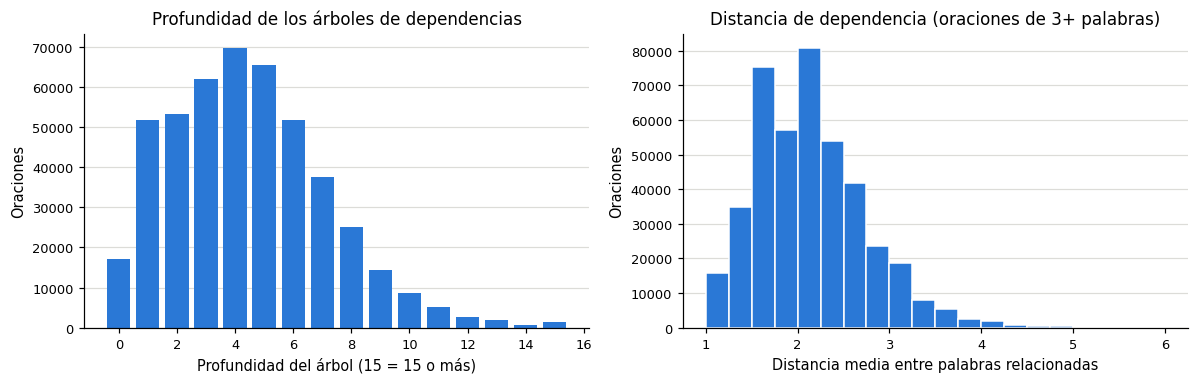

In [9]:
resumen = pd.DataFrame({
    "media": oraciones[["longitud", "profundidad", "distancia", "subordinadas"]].mean(),
    "mediana": oraciones[["longitud", "profundidad", "distancia", "subordinadas"]].median(),
}).round(2)
print(resumen, "\n")
print(f"Oraciones con verbo:                 {oraciones['verbo'].mean():.1%}")
print(f"Oraciones con sujeto:                {oraciones['sujeto'].mean():.1%}")
print(f"Oraciones con alguna subordinada:    {(oraciones['subordinadas'] > 0).mean():.1%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
prof = oraciones["profundidad"].clip(upper=15)
ax1.bar(*np.unique(prof, return_counts=True), color=AZUL, width=0.8)
ax1.set_xlabel("Profundidad del árbol (15 = 15 o más)")
ax1.set_ylabel("Oraciones")
ax1.set_title("Profundidad de los árboles de dependencias")
estilizar(ax1)

dist = oraciones.loc[oraciones["longitud"] >= 3, "distancia"].clip(upper=6)
ax2.hist(dist, bins=np.arange(1, 6.25, 0.25), color=AZUL, edgecolor="white")
ax2.set_xlabel("Distancia media entre palabras relacionadas")
ax2.set_ylabel("Oraciones")
ax2.set_title("Distancia de dependencia (oraciones de 3+ palabras)")
estilizar(ax2)
fig.tight_layout()
plt.show()

Las oraciones del corpus son sintácticamente sencillas. La mayoría de los árboles tiene entre dos
y siete niveles, con el pico en cuatro o cinco, y hay un grupo considerable de árboles muy planos, de
cero a dos niveles, que corresponde a las viñetas: una frase nominal con dos o tres modificadores
colgando directamente del sustantivo. La cola hacia la derecha son los párrafos del perfil de la
empresa, con oraciones largas que encadenan preposiciones y cláusulas relativas.

La distancia de dependencia también es baja: lo típico es que cada palabra esté a unas dos
posiciones de su cabeza. Eso indica que las palabras relacionadas casi siempre van juntas, como en
"excellent communication skills", donde todo cuelga de la palabra de al lado. Es un estilo pensado
para leerse rápido, sin incisos ni frases largas que haya que sostener en la memoria.

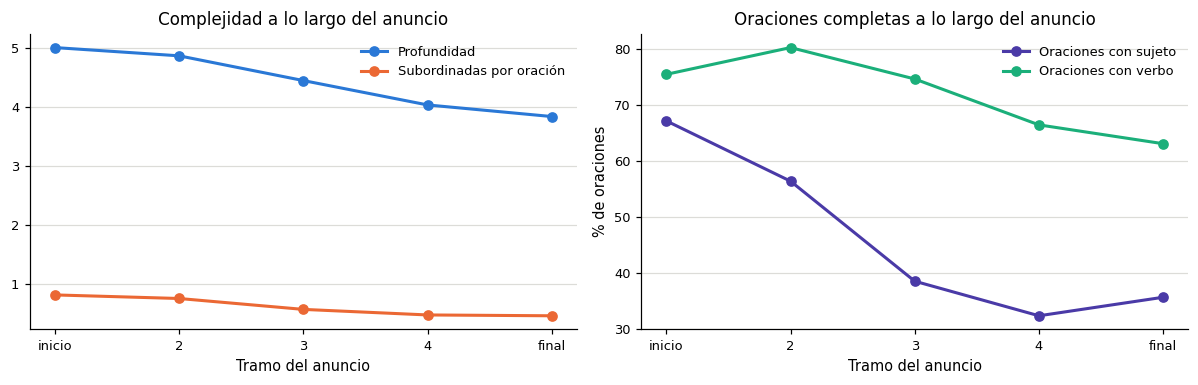

,longitud,profundidad,subordinadas,sujeto,verbo
tramo,,,,,
1,15.53,5.02,0.81,0.67,0.75
2,14.44,4.87,0.75,0.56,0.80
3,12.10,4.45,0.57,0.39,0.75
4,10.42,4.04,0.47,0.32,0.66
5,10.15,3.84,0.46,0.36,0.63


In [10]:
oraciones["tramo"] = np.minimum((5 * oraciones["oracion"] / oraciones["n_oraciones"]).astype(int), 4) + 1
por_tramo = (oraciones[oraciones["n_oraciones"] >= 5]
             .groupby("tramo")[["longitud", "profundidad", "subordinadas", "sujeto", "verbo"]].mean())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(por_tramo.index, por_tramo["profundidad"], "o-", color=AZUL, linewidth=2, label="Profundidad")
ax1.plot(por_tramo.index, por_tramo["subordinadas"], "o-", color=NARANJA, linewidth=2,
         label="Subordinadas por oración")
ax1.set_xticks(range(1, 6), ["inicio", "2", "3", "4", "final"])
ax1.set_xlabel("Tramo del anuncio")
ax1.set_title("Complejidad a lo largo del anuncio")
ax1.legend()
estilizar(ax1)

ax2.plot(por_tramo.index, 100 * por_tramo["sujeto"], "o-", color=MORADO, linewidth=2,
         label="Oraciones con sujeto")
ax2.plot(por_tramo.index, 100 * por_tramo["verbo"], "o-", color=VERDE, linewidth=2,
         label="Oraciones con verbo")
ax2.set_xticks(range(1, 6), ["inicio", "2", "3", "4", "final"])
ax2.set_xlabel("Tramo del anuncio")
ax2.set_ylabel("% de oraciones")
ax2.set_title("Oraciones completas a lo largo del anuncio")
ax2.legend()
estilizar(ax2)
fig.tight_layout()
plt.show()

por_tramo.round(2)

La complejidad baja de forma constante a lo largo del anuncio. Al inicio los árboles son más
profundos y hay más cláusulas subordinadas, porque ahí está el perfil de la empresa, escrito en
prosa. Hacia el final ambas métricas caen, porque llegan los requisitos y las prestaciones en forma
de lista.

La gráfica de la derecha muestra la caída más marcada: las oraciones con sujeto. Al inicio la
mayoría lo tiene ("We are...", "Our team..."), y en la segunda mitad del anuncio pasan a ser una
minoría. Las oraciones con verbo bajan menos, porque muchas viñetas de responsabilidades empiezan con
un verbo pero sin sujeto ("Manage client accounts", "Develop new features"). Es decir, el anuncio
pasa de describir ("we are") a ordenar ("manage") y al final a enumerar ("health insurance").

## 5. Comparación entre ofertas legítimas y fraudulentas

Para comparar las categorías calculo primero el promedio de cada métrica en cada documento, y después
la mediana por categoría. Así cada anuncio pesa lo mismo, sin importar cuántas oraciones tenga.

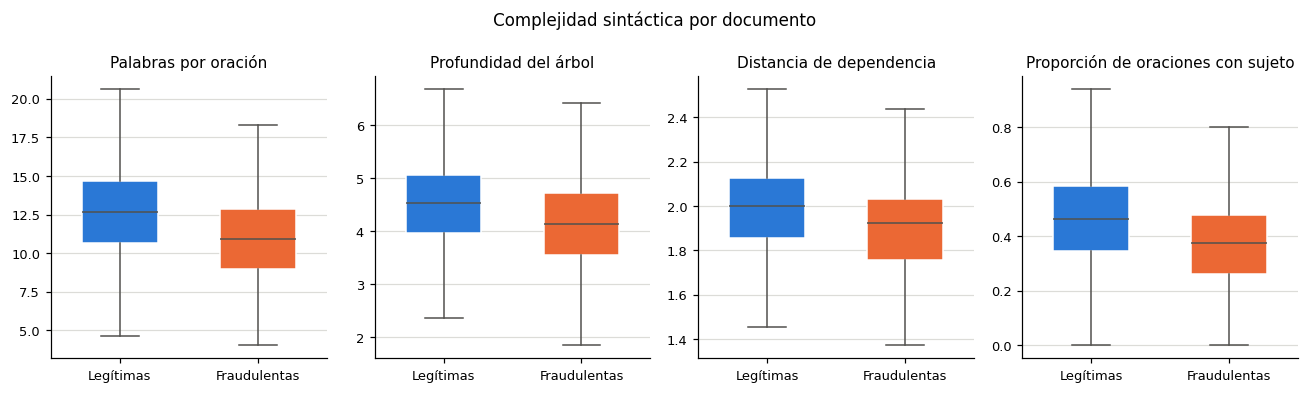

categoria,Fraudulenta,Legítima
longitud,10.900,12.654
profundidad,4.134,4.536
distancia,1.922,1.999
subordinadas,0.434,0.593
sujeto,0.375,0.462
verbo,0.685,0.741


In [11]:
por_doc = (oraciones.groupby(["doc", "categoria", "industria"])
           [["longitud", "profundidad", "distancia", "subordinadas", "sujeto", "verbo"]]
           .mean().reset_index())

metricas = [("longitud", "Palabras por oración"), ("profundidad", "Profundidad del árbol"),
            ("distancia", "Distancia de dependencia"), ("sujeto", "Proporción de oraciones con sujeto")]
fig, ejes = plt.subplots(1, 4, figsize=(12, 3.6))
for ax, (col, titulo) in zip(ejes, metricas):
    datos = [por_doc.loc[por_doc["categoria"] == c, col] for c in ["Legítima", "Fraudulenta"]]
    caja = ax.boxplot(datos, patch_artist=True, widths=0.55, showfliers=False,
                      tick_labels=["Legítimas", "Fraudulentas"])
    for parche, color in zip(caja["boxes"], [AZUL, NARANJA]):
        parche.set_facecolor(color)
        parche.set_edgecolor("white")
    for elemento in ("whiskers", "caps", "medians"):
        for linea in caja[elemento]:
            linea.set_color(GRIS)
    ax.set_title(titulo, fontsize=10)
    estilizar(ax)
fig.suptitle("Complejidad sintáctica por documento", fontsize=11)
fig.tight_layout()
plt.show()

tabla = por_doc.groupby("categoria")[["longitud", "profundidad", "distancia", "subordinadas",
                                      "sujeto", "verbo"]].median().T
tabla.round(3)

En todas las métricas las ofertas fraudulentas salen menos complejas: oraciones más cortas, árboles
menos profundos, menos subordinadas y, sobre todo, menos oraciones con sujeto. La diferencia en
distancia de dependencia es pequeña, así que las palabras relacionadas quedan igual de cerca en las
dos categorías.

Pero hay que tener cuidado al leer esto, porque ya sé que las fraudulentas tienen más viñetas. Si
una categoría tiene más fragmentos sin verbo, su complejidad promedio baja aunque sus oraciones
completas sean igual de complejas. Para separar las dos cosas repito la comparación solo con las
oraciones que sí tienen verbo.

In [12]:
con_verbo = oraciones[oraciones["verbo"]]
por_doc_v = (con_verbo.groupby(["doc", "categoria"])
             [["longitud", "profundidad", "distancia", "subordinadas", "sujeto"]].mean().reset_index())
print("Solo oraciones con verbo (mediana por documento):")
por_doc_v.groupby("categoria")[["longitud", "profundidad", "distancia",
                                "subordinadas", "sujeto"]].median().T.round(3)

Solo oraciones con verbo (mediana por documento):


categoria,Fraudulenta,Legítima
longitud,13.701,15.386
profundidad,4.983,5.333
distancia,2.081,2.162
subordinadas,0.636,0.818
sujeto,0.548,0.652


Al quedarme solo con las oraciones completas, la diferencia prácticamente no cambia. Las oraciones
con verbo de los anuncios fraudulentos siguen siendo más cortas, menos profundas, con menos
subordinadas y con menos sujetos explícitos, más o menos en la misma medida que antes. Así que no es
solo que las fraudulentas tengan más viñetas: sus oraciones completas también son más simples.

La diferencia en sujetos es la que más llama la atención. Una oración con verbo pero sin sujeto suele
ser un imperativo dirigido al lector ("Send your CV", "Apply now"). Esto encaja con lo que encontré en
la Práctica 3, donde las fraudulentas usaban mucho más `your`: el anuncio falso le habla y le da
instrucciones al candidato, en vez de describir quién es la empresa.

Igual que en la Práctica 3, reviso si estas diferencias se sostienen dentro de una misma industria,
para no confundir el fraude con el sector.

In [13]:
principales = por_doc[por_doc["categoria"] == "Fraudulenta"]["industria"].value_counts().head(4).index
filas_ind = []
for industria in principales:
    grupo = por_doc[por_doc["industria"] == industria]
    for categoria, g in grupo.groupby("categoria"):
        filas_ind.append({"industria": industria, "categoria": categoria, "documentos": len(g),
                          "palabras por oración": g["longitud"].median(),
                          "profundidad": g["profundidad"].median(),
                          "subordinadas": g["subordinadas"].median(),
                          "% con sujeto": 100 * g["sujeto"].median()})
pd.DataFrame(filas_ind).set_index(["industria", "categoria"]).round(2)

documentos  palabras por oración  \
industria                 categoria                                       
Oil & Energy              Fraudulenta         107                 11.04   
                          Legítima            130                 12.92   
Accounting                Fraudulenta          46                 10.89   
                          Legítima             72                 12.96   
Hospital & Health Care    Fraudulenta          43                 10.42   
                          Legítima            374                 11.09   
Marketing and Advertising Fraudulenta          36                 10.66   
                          Legítima            660                 12.84   

                                       profundidad  subordinadas  % con sujeto  
industria                 categoria                                             
Oil & Energy              Fraudulenta         4.29          0.43         36.00  
                          Legítima            4.63          0.53         35.29  
Accounting                Fraudulenta         4.00          0.40         33.85  
                          Legítima            4.46          0.50         45.18  
Hospital & Health Care    Fraudulenta         3.68          0.44         39.29  
                          Legítima            4.13          0.49         41.52  
Marketing and Advertising Fraudulenta         3.92          0.53         38.89  
                          Legítima            4.57          0.67         47.06

Aquí el resultado es más firme que en la Práctica 3. En las cuatro industrias las ofertas
fraudulentas tienen oraciones más cortas, árboles menos profundos y menos subordinadas que las
legítimas, así que la menor complejidad no se explica por el sector. Lo único que no se sostiene es la
proporción de oraciones con sujeto: en *Oil & Energy* es igual en las dos categorías, así que no la
tomaría como rasgo del fraude.

Como en las prácticas anteriores, cada industria tiene pocas decenas de anuncios fraudulentos, así
que estos números cambian fácilmente. Lo que sí parece sólido es que el anuncio falso se escribe con
oraciones más cortas y más simples. Visto junto con las prácticas anteriores, el perfil es coherente:
es un texto más corto, que omite a la empresa, que le habla directamente al candidato y que lo hace
con frases breves.

In [14]:
oraciones.to_csv(RUTA / "sintaxis_por_oracion.csv.gz", index=False, compression="gzip")
for nombre in ["corpus_dependencias.jsonl.gz", "sintaxis_por_oracion.csv.gz"]:
    print(f"{nombre:<30} {(RUTA / nombre).stat().st_size / 1024**2:6.1f} MB")

corpus_dependencias.jsonl.gz     34.5 MB
sintaxis_por_oracion.csv.gz       4.2 MB
